In [1]:
!pip install pandas numpy matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
data = {
    'CustomerID': range(101, 116),
    'Gender': ['Male', 'Female', 'Male', 'Female', 'Male',
               'Female', 'Male', 'Female', 'Male', 'Female',
               'Male', 'Female', 'Male', 'Female', 'Male'],

    'Age': [25, 32, 45, 28, 50, 35, 22, 40, 55, 30,
            48, 26, 38, 60, 29],

    'Tenure': [2, 12, 24, 3, 36, 8, 1, 18, 30, 4,
               20, 2, 15, 40, 5],

    'MonthlyCharges': [80, 50, 40, 90, 35, 60, 95, 45,
                       30, 85, 50, 100, 55, 25, 75],

    'SupportCalls': [5, 1, 0, 6, 0, 2, 7, 1, 0, 5,
                     2, 8, 1, 0, 4],

    'Subscription': ['Monthly', 'Yearly', 'Yearly',
                     'Monthly', 'Yearly', 'Monthly',
                     'Monthly', 'Yearly', 'Yearly',
                     'Monthly', 'Yearly', 'Monthly',
                     'Yearly', 'Yearly', 'Monthly'],

    'Churn': ['Yes', 'No', 'No', 'Yes', 'No',
              'No', 'Yes', 'No', 'No', 'Yes',
              'No', 'Yes', 'No', 'No', 'Yes']
}

df = pd.DataFrame(data)

df

,CustomerID,Gender,Age,Tenure,MonthlyCharges,SupportCalls,Subscription,Churn
0,101,Male,25,2,80,5,Monthly,Yes
1,102,Female,32,12,50,1,Yearly,No
2,103,Male,45,24,40,0,Yearly,No
3,104,Female,28,3,90,6,Monthly,Yes
4,105,Male,50,36,35,0,Yearly,No
5,106,Female,35,8,60,2,Monthly,No
6,107,Male,22,1,95,7,Monthly,Yes
7,108,Female,40,18,45,1,Yearly,No
8,109,Male,55,30,30,0,Yearly,No
9,110,Female,30,4,85,5,Monthly,Yes


In [4]:
print("Dataset Information:")
df.info()

print("\nDataset Statistics:")
display(df.describe())

print("\nChurn Count:")
print(df['Churn'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      15 non-null     int64 
 1   Gender          15 non-null     object
 2   Age             15 non-null     int64 
 3   Tenure          15 non-null     int64 
 4   MonthlyCharges  15 non-null     int64 
 5   SupportCalls    15 non-null     int64 
 6   Subscription    15 non-null     object
 7   Churn           15 non-null     object
dtypes: int64(5), object(3)
memory usage: 1.1+ KB

Dataset Statistics:


,CustomerID,Age,Tenure,MonthlyCharges,SupportCalls
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,108.000000,37.533333,14.666667,61.000000,2.800000
std,4.472136,11.728273,12.987173,24.727082,2.782599
min,101.000000,22.000000,1.000000,25.000000,0.000000
25%,104.500000,28.500000,3.500000,42.500000,0.500000
50%,108.000000,35.000000,12.000000,55.000000,2.000000
75%,111.500000,46.500000,22.000000,82.500000,5.000000
max,115.000000,60.000000,40.000000,100.000000,8.000000



Churn Count:
Churn
No     9
Yes    6
Name: count, dtype: int64


In [5]:
total_customers = len(df)

churned_customers = (df['Churn'] == 'Yes').sum()

churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 15
Churned Customers: 6
Churn Rate: 40.0 %


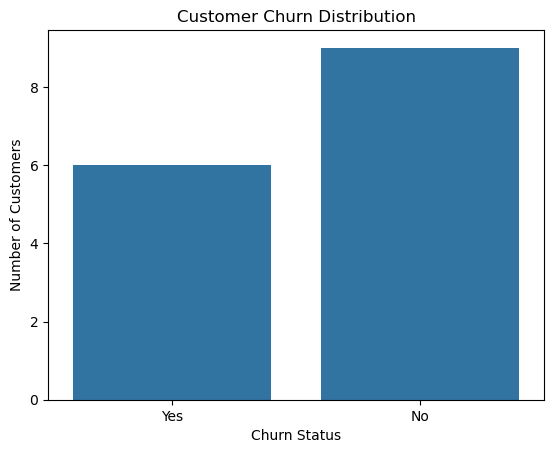

In [6]:
sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

Churn         No  Yes
Subscription         
Monthly        1    6
Yearly         8    0


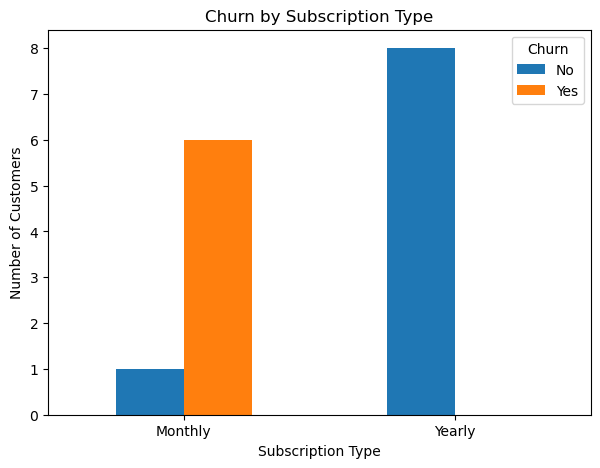

In [7]:
subscription_churn = pd.crosstab(
    df['Subscription'],
    df['Churn']
)

print(subscription_churn)

subscription_churn.plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title("Churn by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

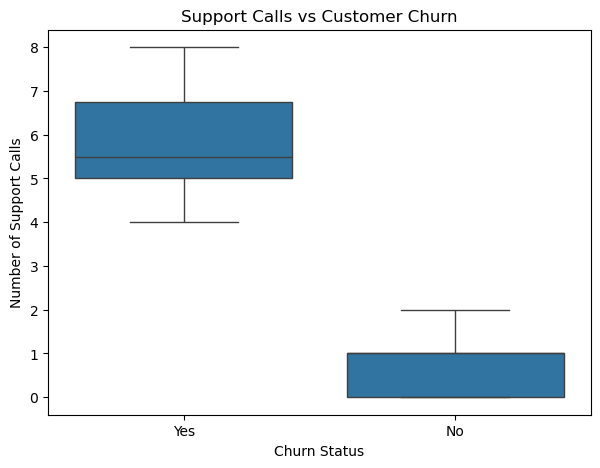

In [8]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='SupportCalls'
)

plt.title("Support Calls vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Support Calls")

plt.show()

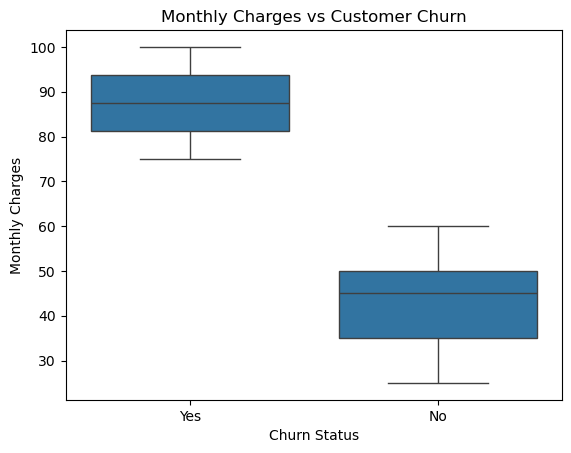

In [9]:
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

In [10]:
print("Average Values Based on Churn:")

display(
    df.groupby('Churn')[
        ['Age', 'Tenure', 'MonthlyCharges', 'SupportCalls']
    ].mean()
)

Average Values Based on Churn:


,Age,Tenure,MonthlyCharges,SupportCalls
Churn,,,,
No,44.777778,22.555556,43.333333,0.777778
Yes,26.666667,2.833333,87.500000,5.833333


In [11]:
df.to_csv("customer_churn_results.csv", index=False)

print("Customer Churn Analysis completed!")
print("Results saved successfully!")

Customer Churn Analysis completed!
Results saved successfully!
